# XGBoost (eXtreme Gradient Boosting)

**XGBoost** — это высокопроизводительная реализация алгоритма градиентного бустинга над решающими деревьями (GBDT), оптимизированная по скорости и качеству предсказаний.

---

### 1. Как это работает (Основная идея)
В отличие от Random Forest, где деревья строятся независимо друг от друга, в бустинге деревья строятся **последовательно**:
1. Строится первое базовое дерево, которое делает первичное предсказание.
2. Вычисляются **ошибки (остатки / градиенты)** этого дерева.
3. Следующее дерево обучается предсказывать именно эти ошибки, чтобы скорректировать результат.
4. Итоговый прогноз — это взвешенная сумма предсказаний всех деревьев.

$$\hat{y}_i = \sum_{k=1}^{K} f_k(x_i), \quad f_k \in \mathcal{F}$$

---

### 2. Ключевые особенности и преимущества
* **Регуляризация (L1 и L2):** В функцию потерь встроены штрафы за сложность деревьев (`reg_alpha`, `reg_lambda`), что снижает риск переобучения по сравнению с классическим Gradient Boosting.
* **Обработка пропусков (`NaN`):** Алгоритм сам определяет оптимальное направление ветвления для пропущенных значений во время обучения.
* **Параллелизм и скорость:** Построение узлов дерева распараллеливается, используется кэш-оптимизация и сжатие данных.
* **Встроенная кросс-валидация и Early Stopping:** Позволяет остановить обучение, как только метрика на валидационной выборке перестает улучшаться.

---

### 3. Главные гиперпараметры

| Параметр | Назначение | Типичные значения |
| :--- | :--- | :--- |
| `n_estimators` | Количество деревьев (итераций бустинга). | `100` – `1000+` |
| `learning_rate` (`eta`) | Шаг обучения (вес каждого нового дерева). Чем меньше, тем больше нужно деревьев. | `0.01` – `0.1` |
| `max_depth` | Максимальная глубина каждого дерева. Контролирует сложность модели. | `3` – `8` |
| `subsample` | Доля случайных строк (объектов) для обучения каждого дерева. | `0.7` – `0.9` |
| `colsample_bytree` | Доля случайных признаков (столбцов) для каждого дерева. | `0.7` – `0.9` |
| `reg_alpha` / `reg_lambda` | L1 (Lasso) и L2 (Ridge) регуляризация весов листьев. | `0` – `10` |
| `early_stopping_rounds` | Остановка обучения, если метрика на валидации не растет $N$ раундов. | `10` – `50` |

In [2]:
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score

# 1. Генерация синтетических данных
X, y = make_classification(
    n_samples=2000, 
    n_features=15, 
    n_informative=10, 
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Инициализация модели
model = xgb.XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    eval_metric="logloss",
    early_stopping_rounds=20,  # Остановится, если за 20 шагов нет улучшений
    random_state=42,
    n_jobs=-1
)

# 3. Обучение с передачей eval_set для работы early_stopping
model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=50  # Выводить лог каждые 50 деревьев (False — отключить)
)

# 4. Предсказание и оценка качества
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print(f"\nЛучшая итерация: {model.best_iteration}")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, y_proba):.4f}")

[0]	validation_0-logloss:0.67441


[50]	validation_0-logloss:0.32200
[100]	validation_0-logloss:0.24321
[150]	validation_0-logloss:0.21416
[200]	validation_0-logloss:0.19997
[250]	validation_0-logloss:0.19132
[277]	validation_0-logloss:0.19079

Лучшая итерация: 257
Accuracy: 0.9275
ROC-AUC:  0.9786


### 4. Важность признаков (Feature Importance) и Регрессия
XGBoost позволяет легко оценить, какие признаки внесли наибольший вклад в принятие решений, а для задач регрессии используется класс `XGBRegressor`.

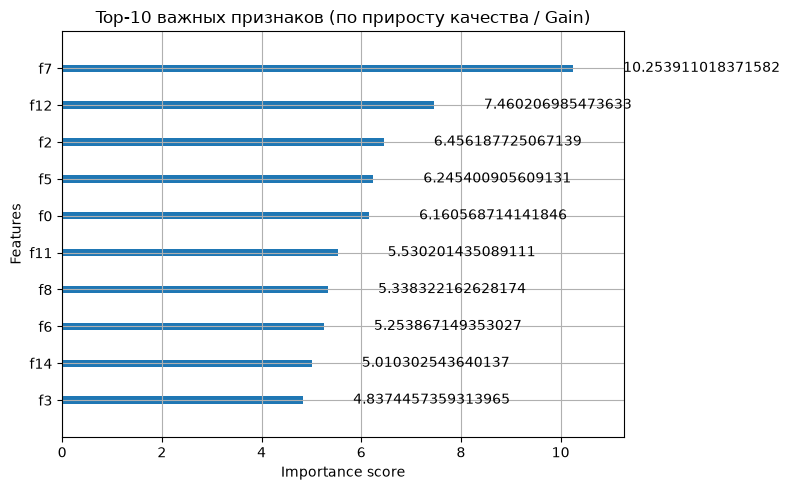

RMSE на тесте: 36.08


In [3]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.metrics import root_mean_squared_error

# --- 1. Важность признаков для обученного классификатора ---
fig, ax = plt.subplots(figsize=(8, 5))
xgb.plot_importance(model, max_num_features=10, importance_type="gain", ax=ax)
plt.title("Top-10 важных признаков (по приросту качества / Gain)")
plt.tight_layout()
plt.show()

# --- 2. Краткий пример для задачи регрессии ---
X_reg, y_reg = make_regression(n_samples=1000, n_features=10, noise=15, random_state=42)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

reg_model = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    objective="reg:squarederror",
    random_state=42
)

reg_model.fit(Xr_train, yr_train)
preds_reg = reg_model.predict(Xr_test)

print(f"RMSE на тесте: {root_mean_squared_error(yr_test, preds_reg):.2f}")